/tmp/ipykernel_24245/3280035370.py:76: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])


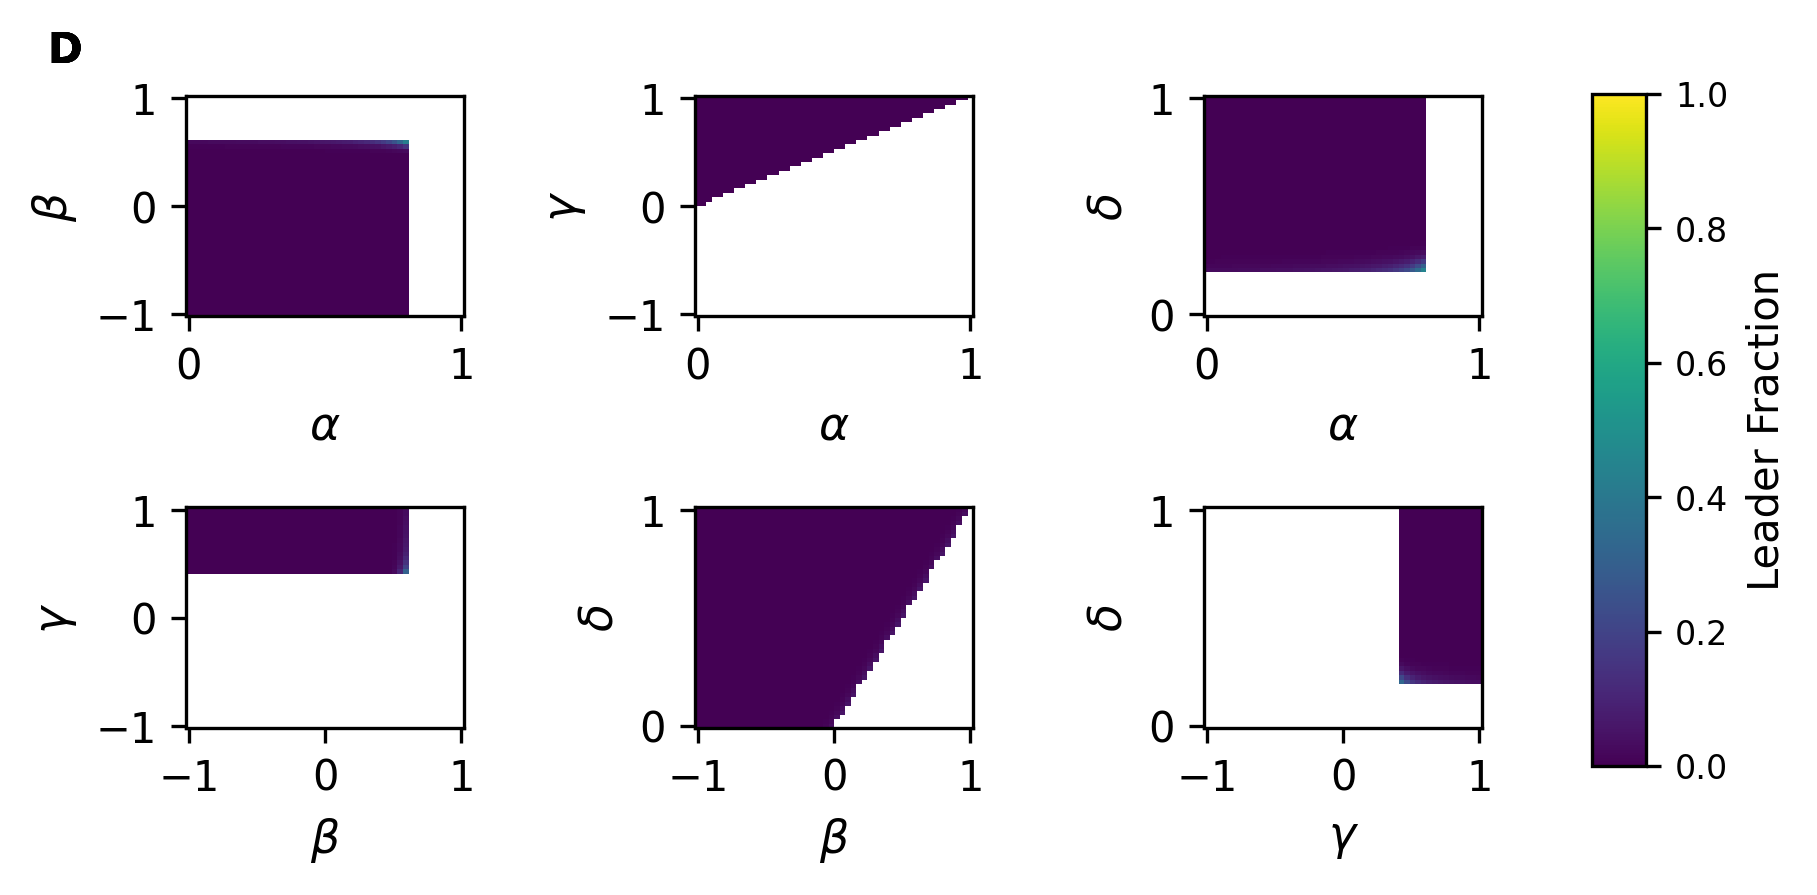

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
import itertools

# Parameter ranges
alpha_values = np.linspace(0, 1, 50)
beta_values = np.linspace(-1, 1, 50)
gamma_values = np.linspace(-1, 1, 50)
delta_values = np.linspace(0, 1.0, 50)

param_ranges = {
    'alpha': alpha_values,
    'beta': beta_values,
    'gamma': gamma_values,
    'delta': delta_values
}

# Baseline
baseline_params = { 'alpha': 0.4, 'beta': 0.2, 'gamma': 0.8, 'delta': 0.6}
param_names = ['alpha', 'beta', 'gamma', 'delta']
param_symbols = {'alpha': r'$\alpha$', 'beta': r'$\beta$', 'gamma': r'$\gamma$', 'delta': r'$\delta$'}

# Fitness functions
def f_L(x, p): return p['alpha'] * x + (p['beta']) * (1 - x)
def f_F(x, p): return ( p['gamma']) * x + (p['delta']) * (1 - x)

# Replicator ODE
def replicator(y, t, p):
    N, x = y
    dN = ((f_L(x, p) - f_F(x, p)) * N * x + f_F(x, p) * N)
    dx = (f_L(x, p) - f_F(x, p)) * x * (1 - x)
    return [dN, dx]

# Time and ICs
N0, x0 = 1e3, 0.5
t = np.linspace(0, 50, 1000)

# Parameter combinations
pairs = list(itertools.combinations(param_names, 2))

# Plotting
fig, axs = plt.subplots(2, 3, figsize=(6, 3.2), dpi=300)
axs = axs.flatten()

for idx, (p1, p2) in enumerate(pairs):
    x_vals, y_vals = param_ranges[p1], param_ranges[p2]
    Z = np.full((len(y_vals), len(x_vals)), np.nan)

    for i, v1 in enumerate(x_vals):
        for j, v2 in enumerate(y_vals):
            p = baseline_params.copy()
            p[p1], p[p2] = v1, v2
            a = p['beta'] - p['delta']
            b =  p['gamma'] - p['alpha']
            if a < 0 and b > 0:
                result = odeint(replicator, [N0, x0], t, args=(p,))
                Z[j, i] = result[-1, 1]

    X, Y = np.meshgrid(x_vals, y_vals)
    c = axs[idx].pcolormesh(X, Y, Z, cmap='viridis', shading='auto', vmin=0, vmax=1)

    axs[idx].set_xlabel(param_symbols[p1], fontsize=11)
    axs[idx].set_ylabel(param_symbols[p2], fontsize=11)
    axs[idx].tick_params(labelsize=10)
    axs[0].annotate('D', xy=(-0.5, 1.3), xycoords='axes fraction',
                fontsize=10, fontweight='bold', va='top', ha='left')
# Shared colorbar
cbar_ax = fig.add_axes([0.92, 0.15, 0.03, 0.7])
cb = fig.colorbar(c, cax=cbar_ax)
cb.set_label('Leader Fraction', fontsize=10)
cb.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
cb.ax.tick_params(labelsize=8)

# Layout
plt.tight_layout(rect=[0, 0, 0.9, 1])
#plt.savefig('leader_proportion_heatmaps_clean.png', dpi=300, bbox_inches='tight')
plt.show()


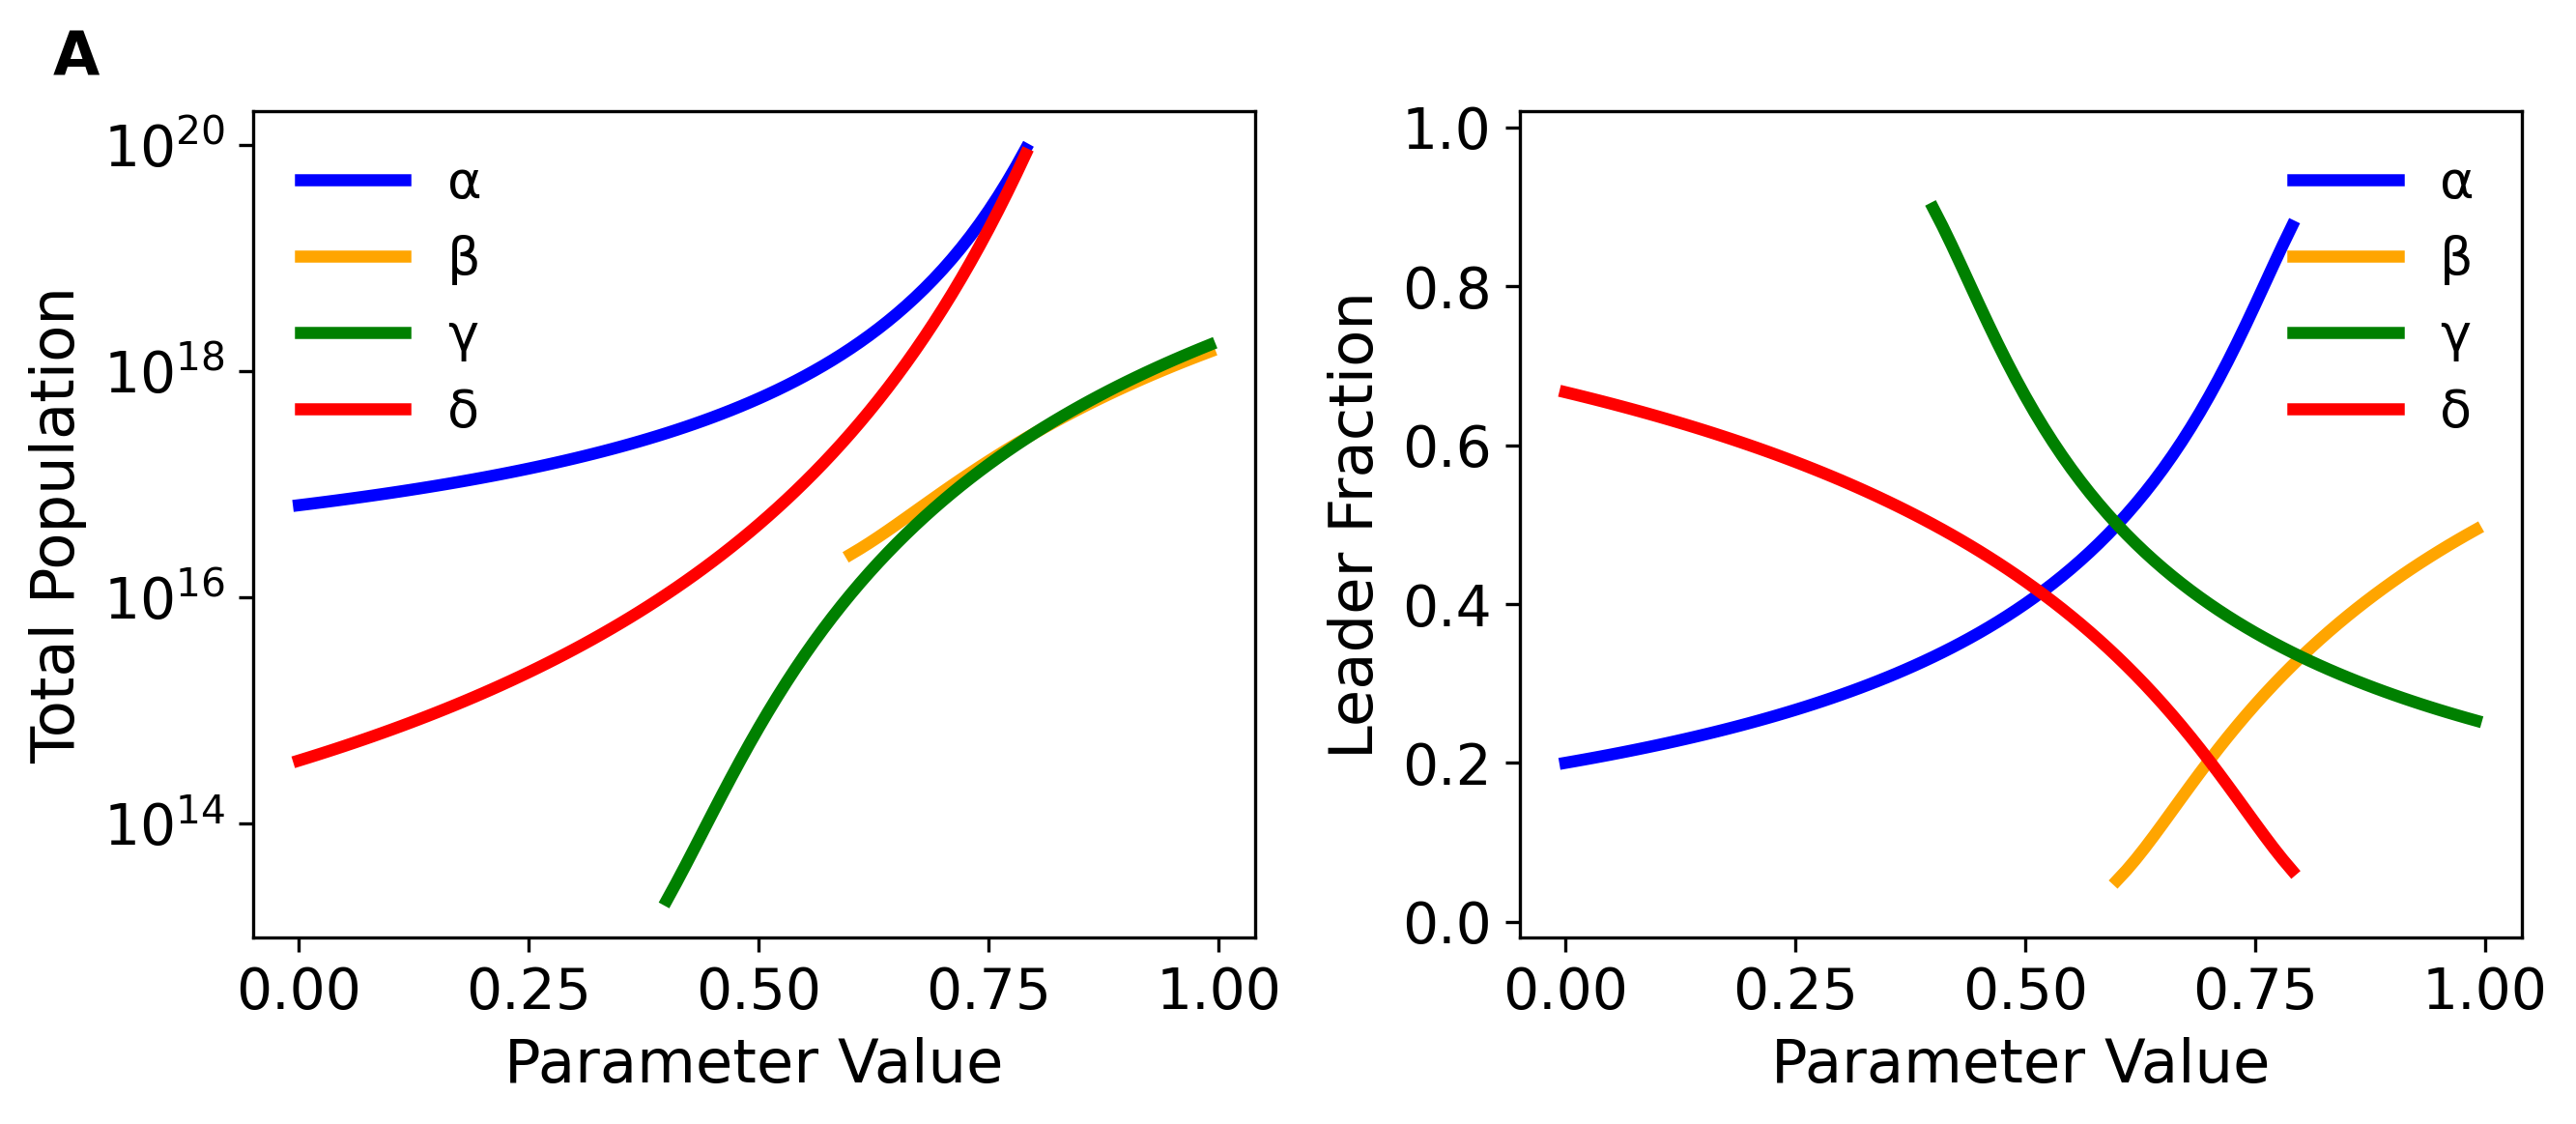

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# Define the parameter ranges
#epsilon_values = np.arange(0, 0.5, 0.01)
alpha_values = np.arange(0, 1, 0.01)
gamma_values = np.arange(-1, 1, 0.01)
delta_values = np.arange(0, 1.0, 0.01)
beta_values = np.arange(-1, 1.0, 0.01)

# Baseline parameters
baseline_params = {

    'alpha': 0.4,
    'beta': 0.8,
    'gamma': 0.8,
    'delta': 0.6,
}

# Parameter names and colors for each parameter
parameter_names = [ 'α', 'β', 'γ', 'δ']
colors = ['blue', 'orange', 'green', 'red']

# Fitness functions
def f_L(x, params):
    alpha = params['alpha']
    beta = params['beta']
    return alpha * x + (beta) * (1 - x)

def f_F(x, params):

    gamma = params['gamma']
    delta = params['delta']
    return ( gamma) * x + (delta) * (1 - x)

# Replicator equations
def replicator_equations(y, t, params):
    N, x = y
    dN_dt = ((f_L(x, params) - f_F(x, params)) * N * x + f_F(x, params) * N)
    dx_dt = (f_L(x, params) - f_F(x, params)) * x * (1 - x)
    return [dN_dt, dx_dt]

# Initial conditions and time points
N0 = 10**3
x0 = 0.5
t = np.linspace(0, 50, 1000)

# Arrays to store final values
final_tumor_sizes = {param: [] for param in parameter_names}
final_leader_proportions = {param: [] for param in parameter_names}
param_values = {param: [] for param in parameter_names}

# Vary each parameter one at a time
for param, original_param in zip(parameter_names, ['alpha', 'beta', 'gamma', 'delta']):
    param_range = eval(f'{original_param}_values')
    for value in param_range:
        # Update parameters
        params = baseline_params.copy()
        params[original_param] = value

        # Calculate a and b to check the condition
        a = params['beta'] - params['delta']
        b = params['gamma'] - params['alpha']

        # Only solve ODEs if a > 0 and b >0
        if a > 0 and b >0:
            # Solve ODEs
            y0 = [N0, x0]
            result = odeint(replicator_equations, y0, t, args=(params,))

            # Store final values
            final_tumor_sizes[param].append(result[-1, 0])
            final_leader_proportions[param].append(result[-1, 1])
            param_values[param].append(value)

# Plotting setup
fig, axs = plt.subplots(1, 2, figsize=(9, 4), dpi=300)

# Plot final tumor sizes
for param, color in zip(parameter_names, colors):
    axs[0].plot(param_values[param], final_tumor_sizes[param], label=f'{param}', color=color, linewidth=3)

axs[0].set_xlabel('Parameter Value', fontsize=15)
axs[0].set_ylabel('Total Population', fontsize=15)
axs[0].set_yscale('log')
axs[0].tick_params(axis='both', labelsize=14)
axs[0].legend(loc='best', fontsize=13, frameon=False)
axs[0].annotate('A', xy=(-0.2, 1.1), xycoords='axes fraction',
                fontsize=15, fontweight='bold', va='top', ha='left')

# Plot final leader cell proportions
for param, color in zip(parameter_names, colors):
    axs[1].plot(param_values[param], final_leader_proportions[param], label=f'{param}', color=color, linewidth=3)

axs[1].set_xlabel('Parameter Value', fontsize=15)
axs[1].set_ylabel('Leader Fraction', fontsize=15)
axs[1].set_ylim(-0.02, 1.02)
axs[1].tick_params(axis='both', labelsize=14)
axs[1].legend(loc='best', fontsize=13, frameon=False)

plt.tight_layout()
plt.show()

